In [1]:
import csv
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, hsv_to_rgb


/Users/malikashahi/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/malikashahi/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# Dataset: all 300 nyc_data images. Every cell processes all of them but only displays the 4 EXAMPLES.
# Nothing is written to disk; everything stays in memory.
DATA_DIR = Path("nyc_data")
IMAGE_PATHS = sorted((DATA_DIR / "images").glob("*.jpg"))

with open(DATA_DIR / "images.csv") as f:
    image_groups = {Path(row["image"]).name: row["group"] for row in csv.DictReader(f)}

# One display example per group
EXAMPLES = {
    "cone_only": "949211189148278.jpg",
    "sign_only": "190258236261020.jpg",
    "both": "808417389786174.jpg",
    "negative": "1606077226268778.jpg",
}

# Annotated objects, one row per object. The annotations contain some near-duplicate boxes for the same
# object (same class, corners within DUPLICATE_TOL pixels), which are dropped.
DUPLICATE_TOL = 3
records = []
with open(DATA_DIR / "annotations.csv") as f:
    for row in csv.DictReader(f):
        name, cls = Path(row["image"]).name, row["class"]
        box = tuple(int(row[key]) for key in ("x0", "y0", "x1", "y1"))
        if not any(r["image"] == name and r["cls"] == cls and max(abs(a - b) for a, b in zip(box, r["box"])) <= DUPLICATE_TOL
                   for r in records):
            records.append({"image": name, "group": image_groups[name], "cls": cls, "box": box})
objects = pd.DataFrame(records)
objects["center"] = [((x0 + x1) // 2, (y0 + y1) // 2) for x0, y0, x1, y1 in objects["box"]]
objects["side"] = [max(x1 - x0, y1 - y0) for x0, y0, x1, y1 in objects["box"]]

# The object windows shown in the histogram displays: the largest cone/sign of each example image
def largest_object(name, cls):
    return objects[(objects["image"] == name) & (objects["cls"] == cls)]["side"].idxmax()

EXAMPLE_OBJECTS = [
    largest_object(EXAMPLES["cone_only"], "cone"),
    largest_object(EXAMPLES["sign_only"], "sign"),
    largest_object(EXAMPLES["both"], "cone"),
    largest_object(EXAMPLES["both"], "sign"),
]

print(f"{len(IMAGE_PATHS)} images {dict(Counter(image_groups.values()))}")
print(f"{len(objects)} annotated objects {dict(Counter(objects['cls']))}")


300 images {'cone_only': 100, 'sign_only': 100, 'both': 40, 'negative': 60}
502 annotated objects {'cone': 313, 'sign': 189}


# Noise Reduction: NLM Denoising

Denoised 300 images


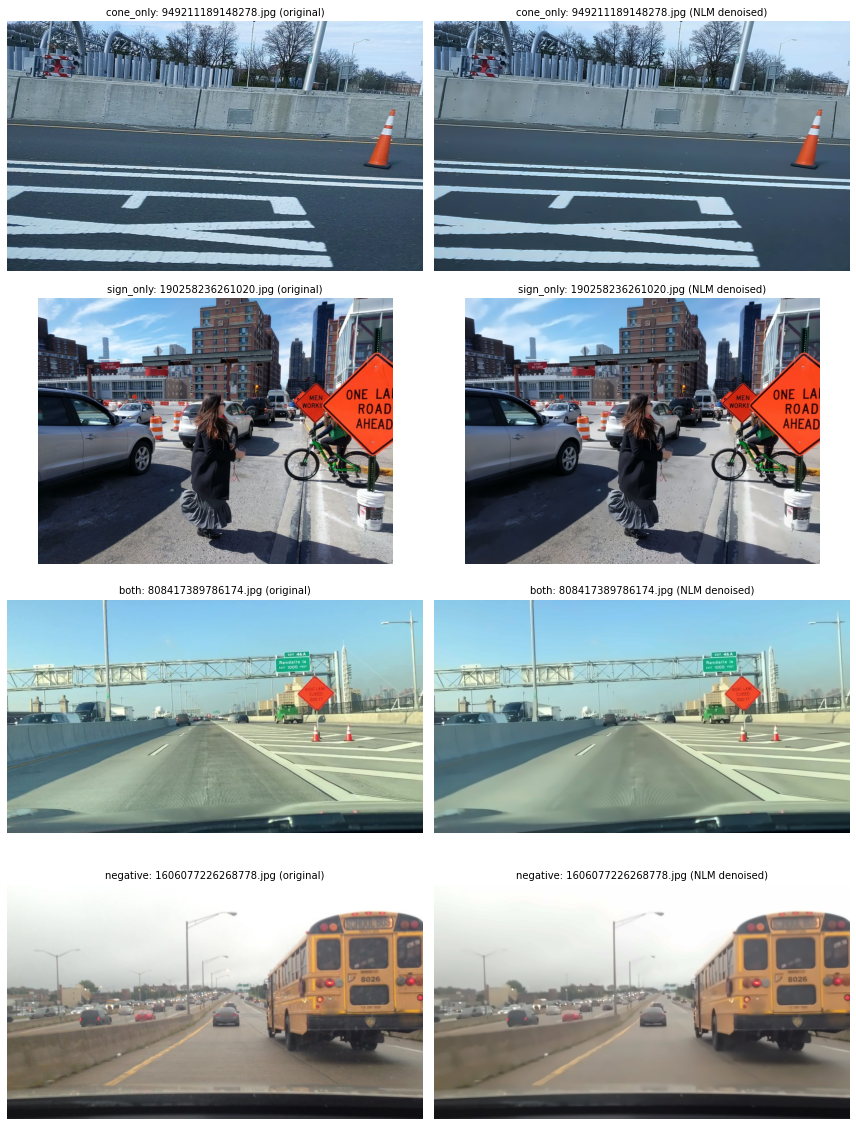

In [3]:
# Apply OpenCV Non-Local Means denoising to every image. Images are denoised in parallel threads and kept in
# memory (about 0.6 GB for all 300); nothing is saved.
# NLM parameters: h = filter strength for luminance, hColor = for color components
h = 5
h_color = 5
template_window_size = 7
search_window_size = 21

def denoise(path):
    return cv2.fastNlMeansDenoisingColored(
        cv2.imread(str(path)), None, h, h_color, template_window_size, search_window_size
    )

with ThreadPoolExecutor() as pool:
    denoised_images = dict(zip((p.name for p in IMAGE_PATHS), pool.map(denoise, IMAGE_PATHS)))
print(f"Denoised {len(denoised_images)} images")

fig, axes = plt.subplots(len(EXAMPLES), 2, figsize=(12, 4 * len(EXAMPLES)), dpi=72)
for row, (group, name) in zip(axes, EXAMPLES.items()):
    original = cv2.imread(str(DATA_DIR / "images" / name))
    for ax, title, im in zip(row, ["original", "NLM denoised"], [original, denoised_images[name]]):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{group}: {name} ({title})", fontsize=10)
        ax.axis("off")
fig.tight_layout()
plt.show()


# HSV Histogram Generation

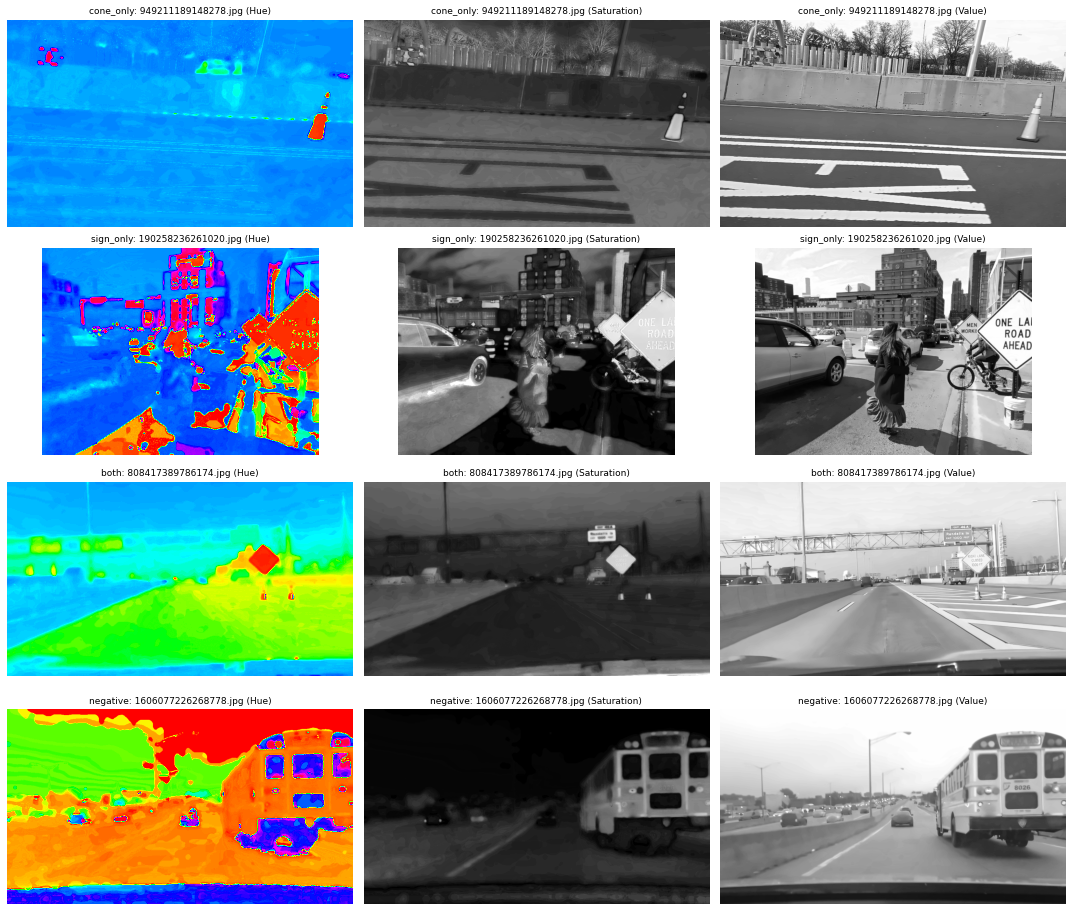

In [4]:
# Convert to HSV (OpenCV ranges: H in [0, 179], S and V in [0, 255]). Conversion is fast, so each cell converts
# an image when it needs it instead of keeping another copy of all 300 images in memory.
def to_hsv(name):
    return cv2.cvtColor(denoised_images[name], cv2.COLOR_BGR2HSV)

def show_channels(convert, titles, cmaps, vmaxes):
    """The three channels of each example image."""
    fig, axes = plt.subplots(len(EXAMPLES), 3, figsize=(15, 3.2 * len(EXAMPLES)), dpi=72)
    for row, (group, name) in zip(axes, EXAMPLES.items()):
        img = convert(name)
        for i, (ax, title, cmap, vmax) in enumerate(zip(row, titles, cmaps, vmaxes)):
            ax.imshow(img[..., i], cmap=cmap, vmin=0, vmax=vmax)
            ax.set_title(f"{group}: {name} ({title})", fontsize=9)
            ax.axis("off")
    fig.tight_layout()
    plt.show()

show_channels(to_hsv, ["Hue", "Saturation", "Value"], ["hsv", "gray", "gray"], [179, 255, 255])


HSV histograms of 502 object windows for each k in [3, 5, 7, 9, 11]


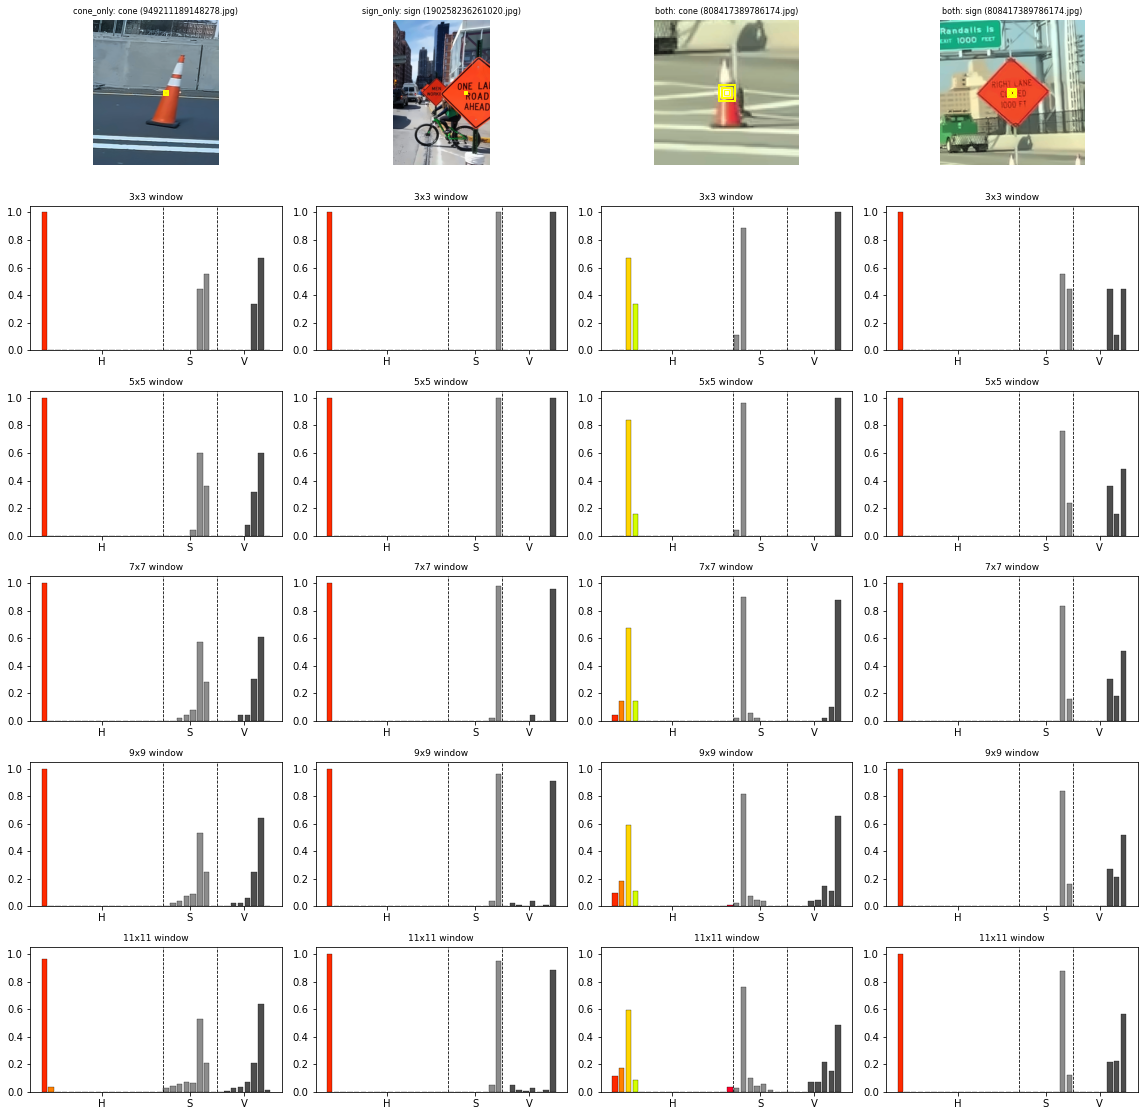

In [5]:
# Local HSV color histograms over k x k windows centered on every annotated object, for each k in K_VALUES.
# Each channel is histogrammed separately: 18 hue bins (10 degrees each), 8 saturation bins, 8 value bins,
# and each histogram is divided by the window's pixel count so its bins sum to 1.
K_VALUES = [3, 5, 7, 9, 11]
BINS = (18, 8, 8)
CHANNEL_MAX = (180, 256, 256)
CLASS_COLORS = {"cone": "orange", "sign": "red"}

def region_histogram(region, bins, channel_max):
    """Per-channel histograms of an image region, each normalized to sum to 1, concatenated."""
    n_pixels = region.shape[0] * region.shape[1]
    return np.concatenate([
        np.bincount((region[..., c].astype(np.int32) * n_bins // max_val).ravel(), minlength=n_bins) / n_pixels
        for c, (n_bins, max_val) in enumerate(zip(bins, channel_max))
    ])

def crop_window(img, center, k):
    """The k x k window centered at (x, y), clipped at the image border."""
    x, y = center
    rows, cols = img.shape[:2]
    return img[max(0, y - k // 2):min(rows, y + k // 2 + 1), max(0, x - k // 2):min(cols, x + k // 2 + 1)]

def window_feature(img, center, k, bins, channel_max):
    """Normalized histogram feature vector of the k x k window centered at (x, y)."""
    return region_histogram(crop_window(img, center, k), bins, channel_max)

# Bar colors: hue bins drawn in their own hue, S and V bins in gray
hue_centers = (np.arange(BINS[0]) + 0.5) / BINS[0]
bar_colors = [hsv_to_rgb((h, 1, 1)) for h in hue_centers] + ["0.55"] * BINS[1] + ["0.3"] * BINS[2]

# Everything the shared helpers need to know about a color space (the Lab section defines LAB the same way)
HSV = dict(convert=to_hsv, to_rgb=cv2.COLOR_HSV2RGB, bins=BINS, channel_max=CHANNEL_MAX,
           colors=bar_colors, channels=("H", "S", "V"))

def object_histograms(space, k=None):
    """Feature vector of every object's k x k window (each object's calculated size if k is None).
    Returns an array of shape (number of objects, sum(bins)), rows in the same order as `objects`."""
    feats = np.zeros((len(objects), sum(space["bins"])))
    for name, rows in objects.groupby("image"):
        img = space["convert"](name)
        for i, obj in rows.iterrows():
            feats[i] = window_feature(img, obj["center"], k or obj["k"], space["bins"], space["channel_max"])
    return feats

def plot_window_hist(ax, hist, title, space):
    bins = space["bins"]
    edges = np.cumsum(bins)
    ax.bar(np.arange(sum(bins)), hist, color=space["colors"], edgecolor="black", lw=0.3)
    for edge in edges[:-1]:
        ax.axvline(edge - 0.5, color="black", ls="--", lw=0.8)
    ax.set_xticks(edges - np.array(bins) / 2 - 0.5, space["channels"])
    ax.set_ylim(0, 1.05)
    ax.set_title(title, fontsize=9)

def show_patch(ax, space, obj, ks):
    """The area around an object with a k x k window drawn for each k in ks."""
    x, y = obj["center"]
    half = max(obj["side"], max(ks), 15)
    img = cv2.cvtColor(space["convert"](obj["image"]), space["to_rgb"])
    x0, y0 = max(0, x - half), max(0, y - half)
    ax.imshow(img[y0:y + half + 1, x0:x + half + 1])
    for k in ks:
        ax.add_patch(plt.Rectangle((x - x0 - k / 2, y - y0 - k / 2), k, k, fill=False, color="yellow", lw=1))
    ax.set_title(f"{obj['group']}: {obj['cls']} ({obj['image']})", fontsize=8)
    ax.axis("off")

def plot_k_hists(space, k_hists):
    """Top row: each example object with its k x k windows. Below: one row of histograms per k."""
    fig = plt.figure(figsize=(16, 2.6 * (len(K_VALUES) + 1)), dpi=72)
    grid = fig.add_gridspec(len(K_VALUES) + 1, len(EXAMPLE_OBJECTS))
    for col, i in enumerate(EXAMPLE_OBJECTS):
        show_patch(fig.add_subplot(grid[0, col]), space, objects.loc[i], K_VALUES)
        for r, k in enumerate(K_VALUES, 1):
            plot_window_hist(fig.add_subplot(grid[r, col]), k_hists[k][i], f"{k}x{k} window", space)
    fig.tight_layout()
    plt.show()

# hsv_k_hists[k] -> (number of objects, 34) histograms of every object's k x k window
hsv_k_hists = {k: object_histograms(HSV, k) for k in K_VALUES}
print(f"HSV histograms of {len(objects)} object windows for each k in {K_VALUES}")
plot_k_hists(HSV, hsv_k_hists)


Calculated detection sizes over all objects:


,count,min,50%,max
cls,,,,
cone,313.0,1.0,17.0,171.0
sign,189.0,1.0,31.0,301.0


cone_only: 949211189148278.jpg
  cone at (877, 220, 955, 365): Calculated detection size: 145x145
sign_only: 190258236261020.jpg
  sign at (744, 245, 842, 362): Calculated detection size: 117x117
  sign at (823, 154, 1022, 455): Calculated detection size: 301x301
  sign at (737, 269, 770, 306): Calculated detection size: 37x37
both: 808417389786174.jpg
  cone at (829, 308, 854, 350): Calculated detection size: 43x43
  cone at (749, 307, 770, 351): Calculated detection size: 45x45
  sign at (715, 189, 804, 275): Calculated detection size: 89x89
negative: 1606077226268778.jpg
  no objects


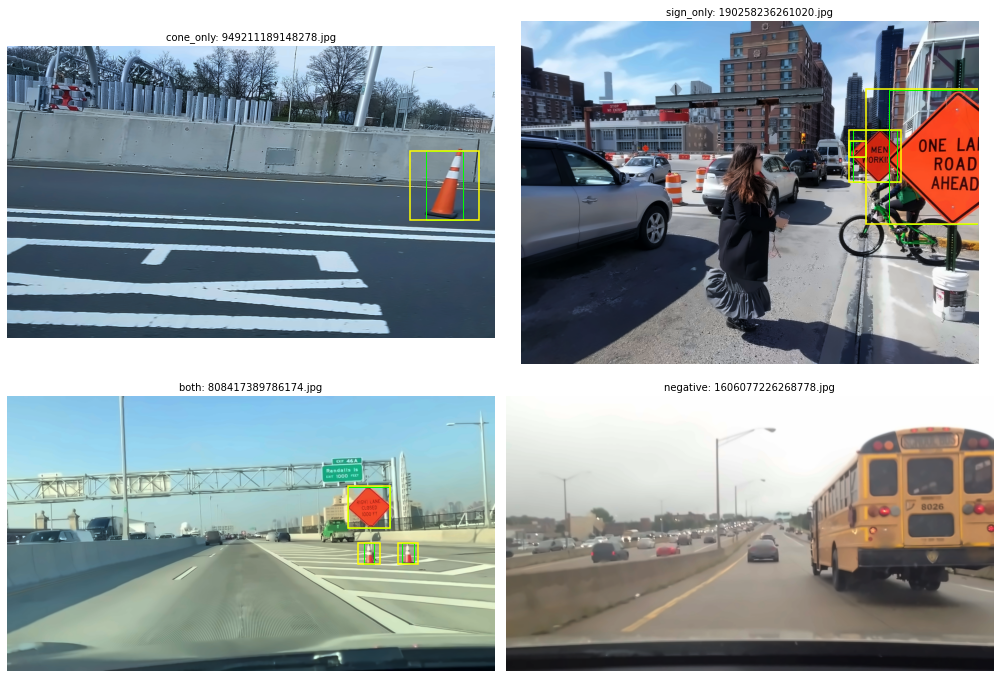

In [6]:
# Detection window size for each annotated object: the window is square, so it needs max(width, height)
# pixels to cover the object, rounded up to odd so it has a center pixel.
objects["k"] = objects["side"] | 1

def print_detection_sizes():
    print("Calculated detection sizes over all objects:")
    display(objects.groupby("cls")["k"].describe()[["count", "min", "50%", "max"]])
    for group, name in EXAMPLES.items():
        print(f"{group}: {name}")
        for _, obj in objects[objects["image"] == name].iterrows():
            print(f"  {obj['cls']} at {obj['box']}: Calculated detection size: {obj['k']}x{obj['k']}")
        if not (objects["image"] == name).any():
            print("  no objects")

def show_detection_windows(space):
    """Annotated boxes in green and each object's k x k detection window in yellow."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=72)
    for ax, (group, name) in zip(axes.flat, EXAMPLES.items()):
        ax.imshow(cv2.cvtColor(space["convert"](name), space["to_rgb"]))
        for _, obj in objects[objects["image"] == name].iterrows():
            x0, y0, x1, y1 = obj["box"]
            (cx, cy), k = obj["center"], obj["k"]
            ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="lime", lw=1))
            ax.add_patch(plt.Rectangle((cx - k / 2, cy - k / 2), k, k, fill=False, color="yellow", lw=1.5))
        ax.set_title(f"{group}: {name}", fontsize=10)
        ax.axis("off")
    fig.tight_layout()
    plt.show()

print_detection_sizes()
show_detection_windows(HSV)


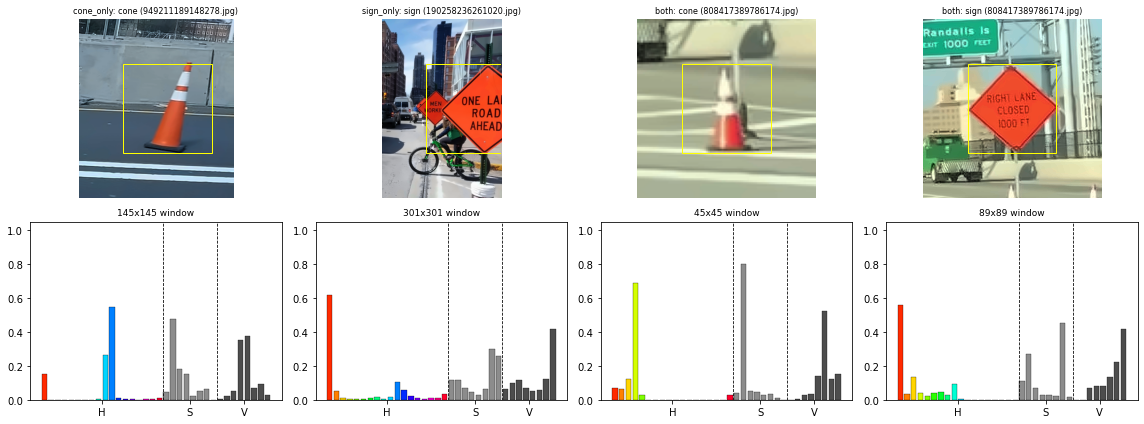

In [7]:
# Local HSV histograms of the example objects at their calculated detection sizes
def plot_calculated_hists(space):
    fig = plt.figure(figsize=(16, 6), dpi=72)
    grid = fig.add_gridspec(2, len(EXAMPLE_OBJECTS))
    for col, i in enumerate(EXAMPLE_OBJECTS):
        obj = objects.loc[i]
        hist = window_feature(space["convert"](obj["image"]), obj["center"], obj["k"], space["bins"], space["channel_max"])
        show_patch(fig.add_subplot(grid[0, col]), space, obj, [obj["k"]])
        plot_window_hist(fig.add_subplot(grid[1, col]), hist, f"{obj['k']}x{obj['k']} window", space)
    fig.tight_layout()
    plt.show()

plot_calculated_hists(HSV)


# Feature Vector Construction for HSV Histogram Generation

HSV feature vectors: (502, 34) (one row per object), every channel's bins sum to 1: True


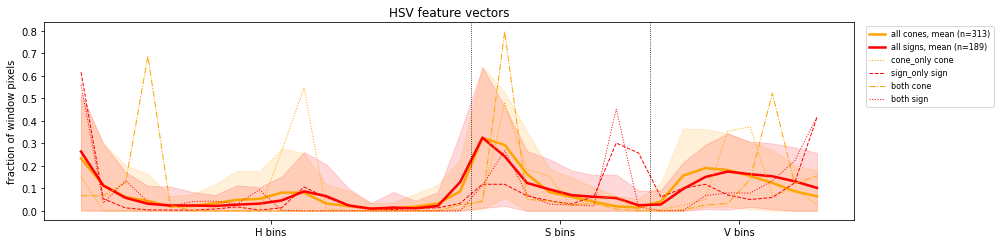

In [8]:
# Feature vector construction: for every annotated object in all 300 images, the H, S and V histograms of its
# detection window (at its calculated size), each divided by the window's pixel count so every channel's bins
# sum to 1, concatenated into one feature vector of sum(BINS) = 34 values.
def check_normalized(feats, bins):
    sums = np.stack([part.sum(axis=1) for part in np.split(feats, np.cumsum(bins)[:-1], axis=1)], axis=1)
    return np.allclose(sums, 1)

def plot_feature_vectors(space, feats, title):
    """Mean feature vector of each class over all objects (shaded band = 1 standard deviation),
    plus the example objects' vectors as thin lines."""
    bins = space["bins"]
    edges = np.cumsum(bins)
    x = np.arange(sum(bins))
    fig, ax = plt.subplots(figsize=(14, 3.5), dpi=72)
    for cls, color in CLASS_COLORS.items():
        f = feats[(objects["cls"] == cls).to_numpy()]
        mean, std = f.mean(axis=0), f.std(axis=0)
        ax.plot(x, mean, color=color, lw=2.5, label=f"all {cls}s, mean (n={len(f)})")
        ax.fill_between(x, np.maximum(mean - std, 0), mean + std, color=color, alpha=0.15)
    for i, ls in zip(EXAMPLE_OBJECTS, [":", "--", "-.", ":"]):
        obj = objects.loc[i]
        ax.plot(x, feats[i], color=CLASS_COLORS[obj["cls"]], lw=1, ls=ls, label=f"{obj['group']} {obj['cls']}")
    for edge in edges[:-1]:
        ax.axvline(edge - 0.5, color="black", ls=":", lw=0.8)
    ax.set_xticks(edges - np.array(bins) / 2 - 0.5, [f"{c} bins" for c in space["channels"]])
    ax.set_ylabel("fraction of window pixels")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    plt.show()

# hsv_features[i] -> feature vector of objects.loc[i]
hsv_features = object_histograms(HSV)
print(f"HSV feature vectors: {hsv_features.shape} (one row per object), "
      f"every channel's bins sum to 1: {check_normalized(hsv_features, BINS)}")
plot_feature_vectors(HSV, hsv_features, "HSV feature vectors")


# Desciptive Statistics for HSV Histogram Generation 

In [9]:
# Descriptive statistics of every object's window, from its histogram p(r_i) over every level r_i
# (H: 0-179, S and V: 0-255), using the formulas from the slides.
# Note: hue is circular (0 and 179 are both red), so hue mean/median can be misleading for red windows.
ALPHA = 0.1  # alpha-trimmed mean: drop this fraction of pixels from each tail
STAT_NAMES = ["mean", "trimmed mean", "median", "mode", "std"]

def histogram_stats(p, alpha=ALPHA):
    """Mean, alpha-trimmed mean, median, mode and standard deviation of a normalized histogram p."""
    r = np.arange(len(p))
    mean = np.sum(r * p)
    std = np.sqrt(np.sum((r - mean) ** 2 * p))
    cdf = np.cumsum(p)
    median = np.searchsorted(cdf, 0.5)
    mode = np.argmax(p)
    # Each level owns the probability interval [cdf - p, cdf]; keep only the part inside [alpha, 1 - alpha]
    kept = np.clip(np.minimum(cdf, 1 - alpha) - np.maximum(cdf - p, alpha), 0, None)
    trimmed_mean = np.sum(r * kept) / kept.sum()
    return np.array([mean, trimmed_mean, median, mode, std])

def window_stats(img, center, k, channel_max):
    """Descriptive statistics of every channel of a k x k window, concatenated."""
    window = crop_window(img, center, k)
    return np.concatenate([
        histogram_stats(np.bincount(window[..., c].ravel(), minlength=levels) / window[..., c].size)
        for c, levels in enumerate(channel_max)
    ])

def object_stats(space):
    """Statistics of every object's window at its calculated size: one row per object."""
    stats = np.zeros((len(objects), len(STAT_NAMES) * len(space["channels"])))
    for name, rows in objects.groupby("image"):
        img = space["convert"](name)
        for i, obj in rows.iterrows():
            stats[i] = window_stats(img, obj["center"], obj["k"], space["channel_max"])
    return pd.DataFrame(stats, index=objects.index,
                        columns=pd.MultiIndex.from_product([space["channels"], STAT_NAMES]))

def show_stats(stats):
    print("Average of each statistic per class, over all objects:")
    display(stats.groupby(objects["cls"]).mean().round(1))
    print("Example objects:")
    display(stats.loc[EXAMPLE_OBJECTS].set_axis(
        pd.MultiIndex.from_frame(objects.loc[EXAMPLE_OBJECTS, ["group", "cls"]])).round(1))

hsv_stats = object_stats(HSV)
show_stats(hsv_stats)


Average of each statistic per class, over all objects:


H                                     S                            \
      mean trimmed mean median  mode   std  mean trimmed mean median  mode   
cls                                                                          
cone  66.0         64.7   64.6  60.7  30.3  64.9         61.6   57.6  56.7   
sign  68.1         66.1   64.6  60.0  36.7  75.4         73.8   72.7  76.2   

                V                                   
       std   mean trimmed mean median   mode   std  
cls                                                 
cone  33.5  121.2        120.6  120.3  129.8  37.8  
sign  38.3  139.0        140.2  142.0  155.1  43.1

Example objects:


H                                       S               \
                mean trimmed mean median   mode   std   mean trimmed mean   
group     cls                                                               
cone_only cone  87.6         94.4  100.0  105.0  36.1   80.4         72.4   
sign_only sign  40.7         31.8    6.0    6.0  54.1  158.5        165.0   
both      cone  34.4         32.5   34.0   36.0  25.8   53.3         44.2   
          sign  23.9         19.0    5.0    4.0  27.8  130.4        132.7   

                                        V                                   
               median   mode   std   mean trimmed mean median   mode   std  
group     cls                                                               
cone_only cone   58.0   38.0  50.4  138.1        136.0  149.0  151.0  40.8  
sign_only sign  210.0  255.0  83.1  170.1        177.6  202.0  254.0  83.6  
both      cone   40.0   44.0  35.2  178.1        177.9  171.0  164.0  36.9  
          sign  146.0  208.0  80.0  195.8        202.1  202.0  243.0  51.0

# Similarity Matching for HSV Histograms

Correct matches: 293 of 502 (58%)


match,False,cone,sign
true class,,,
cone,29,206,78
sign,29,73,87


Example objects:


,image,group,cls,D3 to cone,D3 to sign,match
37,949211189148278.jpg,cone_only,cone,0.833,1.185,cone
262,190258236261020.jpg,sign_only,sign,0.833,0.874,cone
494,808417389786174.jpg,both,cone,1.389,2.052,False
495,808417389786174.jpg,both,sign,1.496,1.009,sign


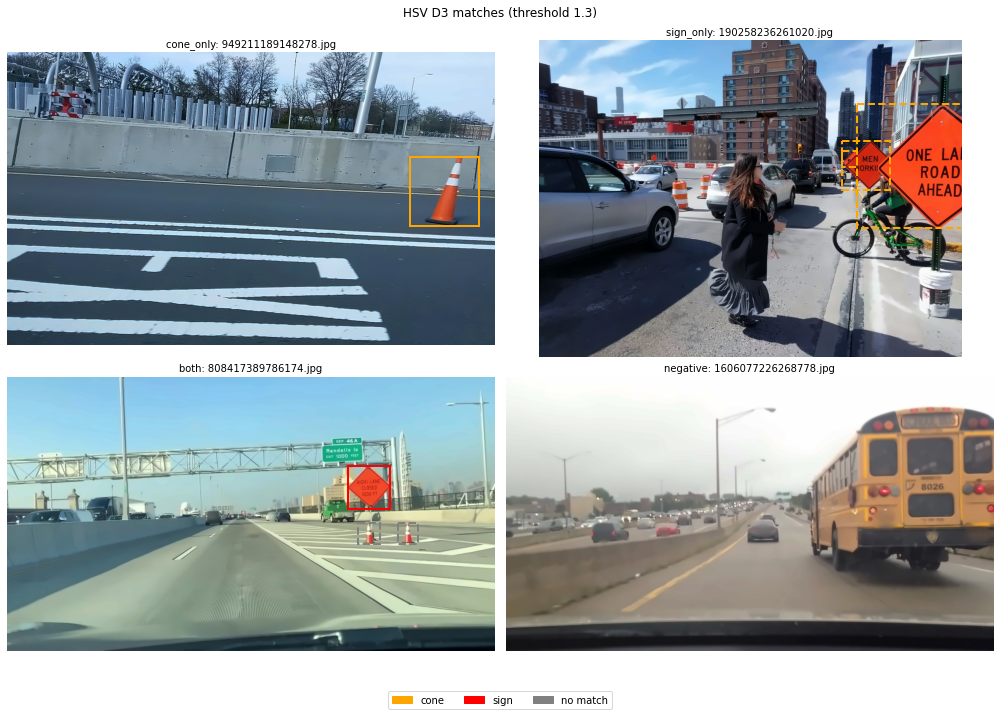

In [10]:
# Similarity matching with the D3 distance from the slides: sum((a - b)^2 / max(a, b)).
# Leave-one-image-out: the database of known object histograms for an image is every annotated cone and sign in
# the OTHER 299 images, so an object is never compared with itself. An object matches the class of its closest
# database entry if that D3 distance is at most D3_THRESHOLD; otherwise it is not a match (False).
D3_THRESHOLD = 1.3  # placeholder: to be tuned with precision/recall
OBJECT_CLASSES = ["cone", "sign"]
MATCH_COLORS = {**CLASS_COLORS, False: "gray"}

def d3(a, b):
    """D3 distance between feature vector a and each row of b."""
    m = np.maximum(a, b)
    # Bins that are empty in both histograms contribute 0
    return np.sum(np.divide((a - b) ** 2, m, out=np.zeros_like(m), where=m > 0), axis=-1)

def match_objects(feats, threshold):
    """Match every object against the objects of all other images. One row per object."""
    classes, images = objects["cls"].to_numpy(), objects["image"].to_numpy()
    records = []
    for vec, image in zip(feats, images):
        others = images != image
        dists = d3(vec, feats[others])
        best = {c: dists[classes[others] == c].min() for c in OBJECT_CLASSES}
        nearest = min(best, key=best.get)
        records.append({**{f"D3 to {c}": best[c] for c in OBJECT_CLASSES},
                        "match": nearest if best[nearest] <= threshold else False})
    return objects[["image", "group", "cls"]].join(pd.DataFrame(records, index=objects.index))

def summarize_matches(matches):
    correct = matches["match"] == matches["cls"]
    print(f"Correct matches: {correct.sum()} of {len(matches)} ({correct.mean():.0%})")
    display(pd.crosstab(matches["cls"].rename("true class"), matches["match"].astype(str).rename("match")))
    print("Example objects:")
    display(matches.loc[EXAMPLE_OBJECTS].round(3))

def show_matches(space, matches, title):
    """Every object in the example images, colored by its match (gray = no match), solid if correct, dashed if wrong."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=72)
    for ax, (group, name) in zip(axes.flat, EXAMPLES.items()):
        ax.imshow(cv2.cvtColor(space["convert"](name), space["to_rgb"]))
        for i, obj in objects[objects["image"] == name].iterrows():
            (x, y), k, matched = obj["center"], obj["k"], matches.at[i, "match"]
            ax.add_patch(plt.Rectangle((x - k / 2, y - k / 2), k, k, fill=False, color=MATCH_COLORS[matched], lw=2,
                                       ls="-" if matched == obj["cls"] else "--"))
        ax.set_title(f"{group}: {name}", fontsize=10)
        ax.axis("off")
    fig.suptitle(title)
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=l or "no match") for l, c in MATCH_COLORS.items()],
               loc="lower center", ncol=3)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()

hsv_matches = match_objects(hsv_features, D3_THRESHOLD)
summarize_matches(hsv_matches)
show_matches(HSV, hsv_matches, f"HSV D3 matches (threshold {D3_THRESHOLD})")


# Lab Histogram Generation

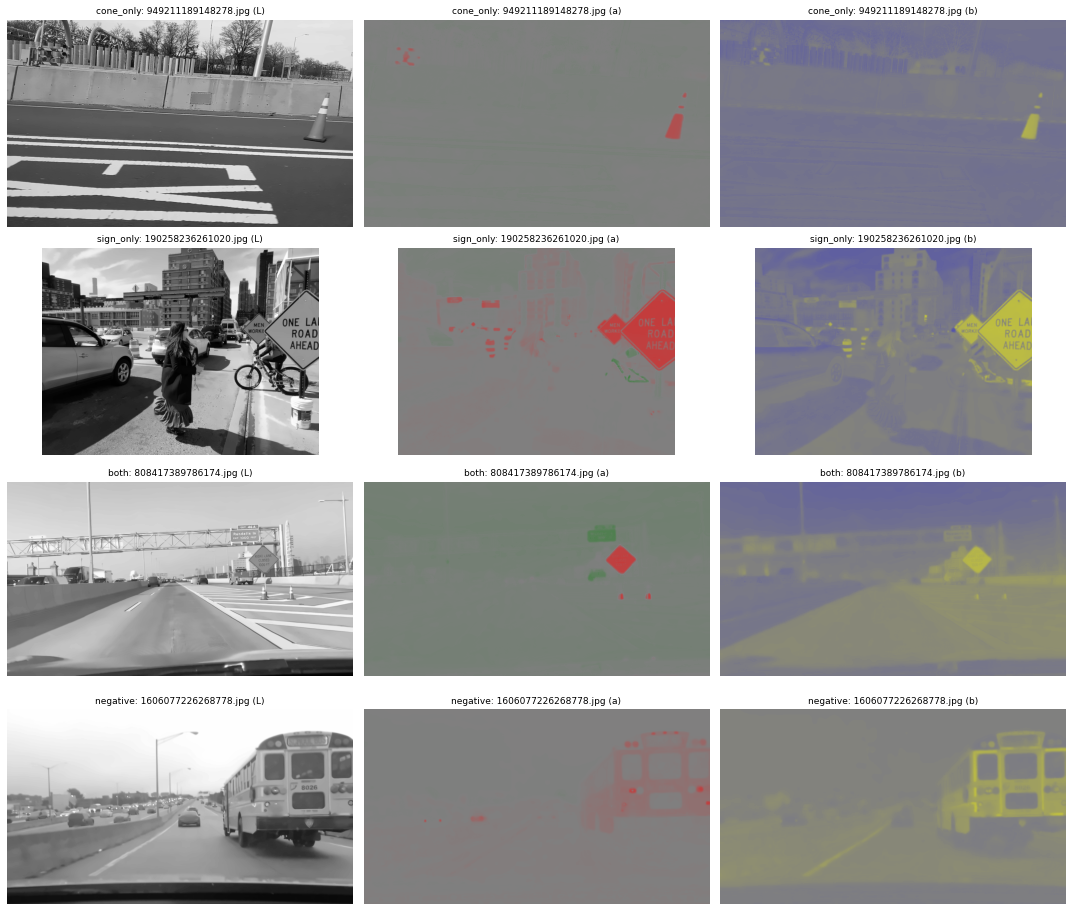

In [11]:
# Convert to CIE Lab. OpenCV 8-bit ranges: L in [0, 255] (L* scaled by 255/100),
# a and b in [0, 255] with 128 = neutral (a: green -> red, b: blue -> yellow)
def to_lab(name):
    return cv2.cvtColor(denoised_images[name], cv2.COLOR_BGR2LAB)

lab_cmaps = [
    "gray",
    LinearSegmentedColormap.from_list("a", ["green", "0.5", "red"]),
    LinearSegmentedColormap.from_list("b", ["blue", "0.5", "yellow"]),
]
show_channels(to_lab, ["L", "a", "b"], lab_cmaps, [255, 255, 255])


Lab histograms of 502 object windows for each k in [3, 5, 7, 9, 11]


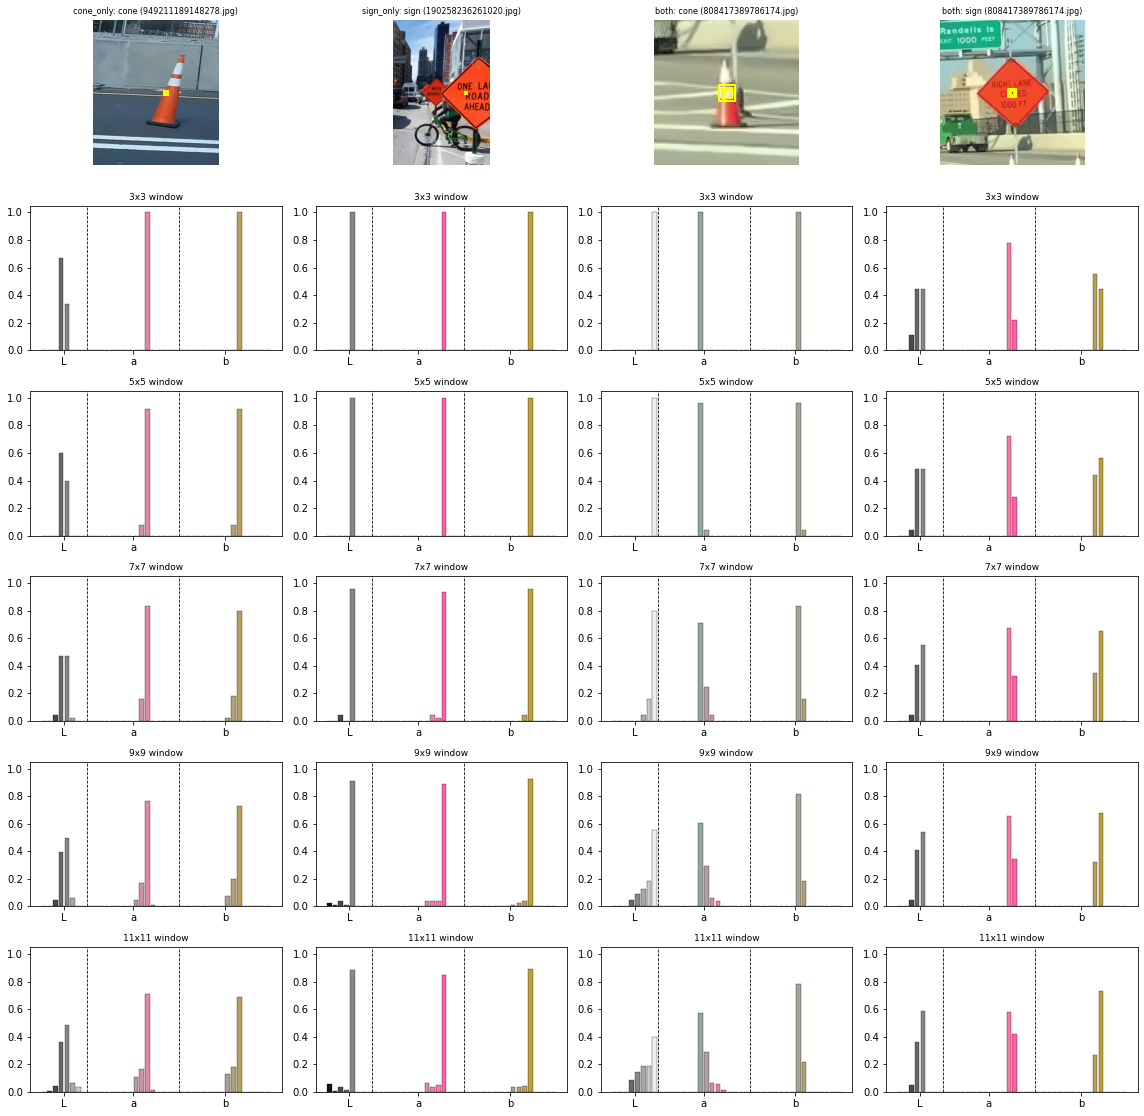

In [12]:
# Local Lab color histograms over k x k windows centered on every annotated object, for each k in K_VALUES.
# 8 lightness bins, 16 bins each for a and b (orange shows up as high a and high b).
LAB_BINS = (8, 16, 16)
LAB_CHANNEL_MAX = (256, 256, 256)

def lab_bin_color(L, a, b):
    return cv2.cvtColor(np.uint8([[[L, a, b]]]), cv2.COLOR_LAB2RGB)[0, 0] / 255

# Bar colors: each bin drawn in the color it represents (a and b bins at medium lightness)
bin_centers = lambda n: ((np.arange(n) + 0.5) * 256 / n).astype(int)
lab_bar_colors = ([lab_bin_color(c, 128, 128) for c in bin_centers(LAB_BINS[0])]
                  + [lab_bin_color(170, c, 128) for c in bin_centers(LAB_BINS[1])]
                  + [lab_bin_color(170, 128, c) for c in bin_centers(LAB_BINS[2])])

LAB = dict(convert=to_lab, to_rgb=cv2.COLOR_LAB2RGB, bins=LAB_BINS, channel_max=LAB_CHANNEL_MAX,
           colors=lab_bar_colors, channels=("L", "a", "b"))

# lab_k_hists[k] -> (number of objects, 40) histograms of every object's k x k window
lab_k_hists = {k: object_histograms(LAB, k) for k in K_VALUES}
print(f"Lab histograms of {len(objects)} object windows for each k in {K_VALUES}")
plot_k_hists(LAB, lab_k_hists)


Calculated detection sizes over all objects:


,count,min,50%,max
cls,,,,
cone,313.0,1.0,17.0,171.0
sign,189.0,1.0,31.0,301.0


cone_only: 949211189148278.jpg
  cone at (877, 220, 955, 365): Calculated detection size: 145x145
sign_only: 190258236261020.jpg
  sign at (744, 245, 842, 362): Calculated detection size: 117x117
  sign at (823, 154, 1022, 455): Calculated detection size: 301x301
  sign at (737, 269, 770, 306): Calculated detection size: 37x37
both: 808417389786174.jpg
  cone at (829, 308, 854, 350): Calculated detection size: 43x43
  cone at (749, 307, 770, 351): Calculated detection size: 45x45
  sign at (715, 189, 804, 275): Calculated detection size: 89x89
negative: 1606077226268778.jpg
  no objects


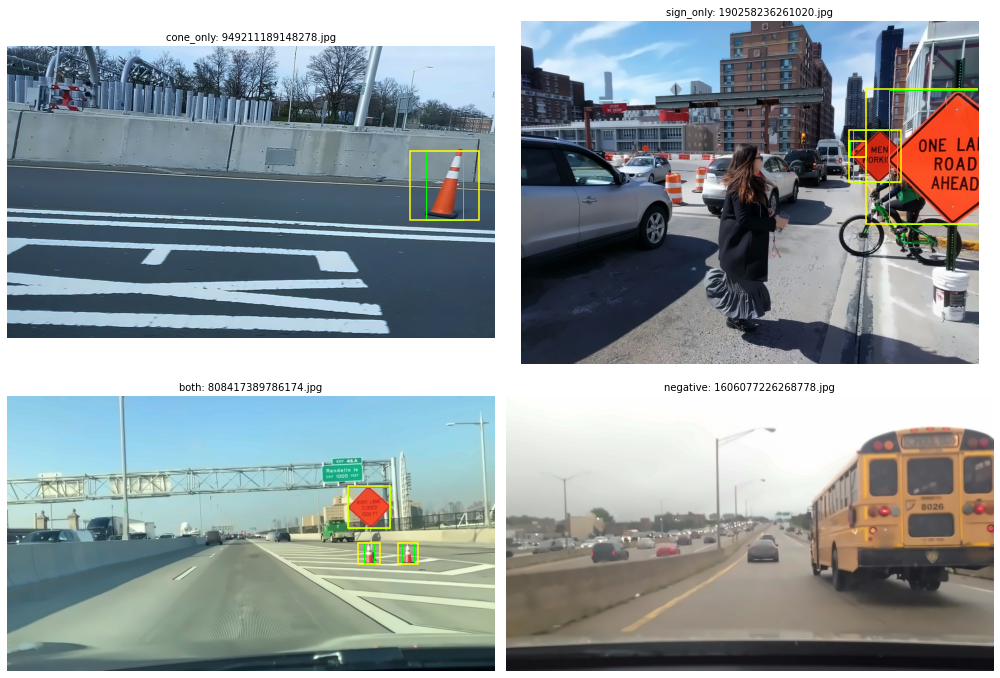

In [13]:
# Calculated detection window sizes (computed in the HSV section; they depend only on the object boxes)
print_detection_sizes()
show_detection_windows(LAB)


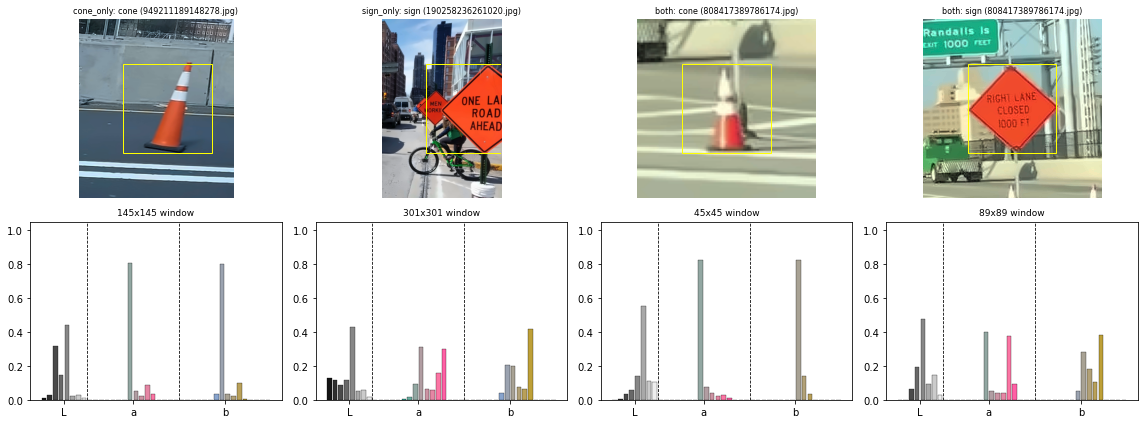

In [14]:
# Local Lab histograms of the example objects at their calculated detection sizes
plot_calculated_hists(LAB)


# Feature Vector Construction for Lab Histogram Generation

Lab feature vectors: (502, 40) (one row per object), every channel's bins sum to 1: True


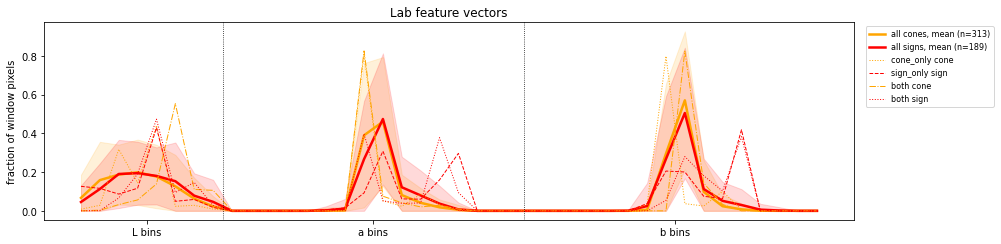

In [15]:
# Lab feature vectors: for every annotated object, the L, a and b histograms of its detection window (at its
# calculated size), each divided by the window's pixel count, concatenated into sum(LAB_BINS) = 40 values.
# lab_features[i] -> feature vector of objects.loc[i]
lab_features = object_histograms(LAB)
print(f"Lab feature vectors: {lab_features.shape} (one row per object), "
      f"every channel's bins sum to 1: {check_normalized(lab_features, LAB_BINS)}")
plot_feature_vectors(LAB, lab_features, "Lab feature vectors")


# Desciptive Statistics for Lab Histogram Generation 

In [16]:
# Descriptive statistics of every object's Lab window, from its histogram p(r_i) over every level r_i (0-255).
# Values are in OpenCV 8-bit units: L* = L * 100 / 255, and a* = a - 128, b* = b - 128 (128 = neutral).
lab_stats = object_stats(LAB)
show_stats(lab_stats)


Average of each statistic per class, over all objects:


L                                       a                      \
       mean trimmed mean median   mode   std   mean trimmed mean median   
cls                                                                       
cone  111.4        111.1  111.5  110.4  34.8  132.9        131.7  130.2   
sign  123.0        123.7  125.5  134.1  38.6  136.8        136.4  135.4   

                       b                                  
       mode   std   mean trimmed mean median   mode  std  
cls                                                       
cone  128.1   8.6  132.9        132.2  131.5  130.4  5.9  
sign  134.4  10.0  135.3        134.8  133.9  132.3  8.7

Example objects:


L                                       a               \
                 mean trimmed mean median   mode   std   mean trimmed mean   
group     cls                                                                
cone_only cone  122.7        122.4  128.0  148.0  36.7  131.2        126.9   
sign_only sign  115.2        116.5  143.0  147.0  57.4  161.0        162.1   
both      cone  173.9        174.5  173.0  169.0  35.7  127.6        123.6   
          sign  146.9        145.9  143.0  143.0  35.6  157.1        157.7   

                                        b                                   
               median   mode   std   mean trimmed mean median   mode   std  
group     cls                                                               
cone_only cone  125.0  123.0  16.1  125.8        121.9  121.0  123.0  16.9  
sign_only sign  163.0  192.0  30.2  155.6        156.8  154.0  187.0  29.0  
both      cone  123.0  121.0  14.8  142.8        141.8  142.0  141.0   5.3  
          sign  166.0  191.0  32.2  158.1        158.9  155.0  182.0  21.1

# Similarity Matching for Lab Histograms

Correct matches: 304 of 502 (61%)


match,False,cone,sign
true class,,,
cone,1,218,94
sign,4,99,86


Example objects:


,image,group,cls,D3 to cone,D3 to sign,match
37,949211189148278.jpg,cone_only,cone,0.606,0.900,cone
262,190258236261020.jpg,sign_only,sign,1.241,0.915,sign
494,808417389786174.jpg,both,cone,0.458,0.628,cone
495,808417389786174.jpg,both,sign,1.432,0.865,sign


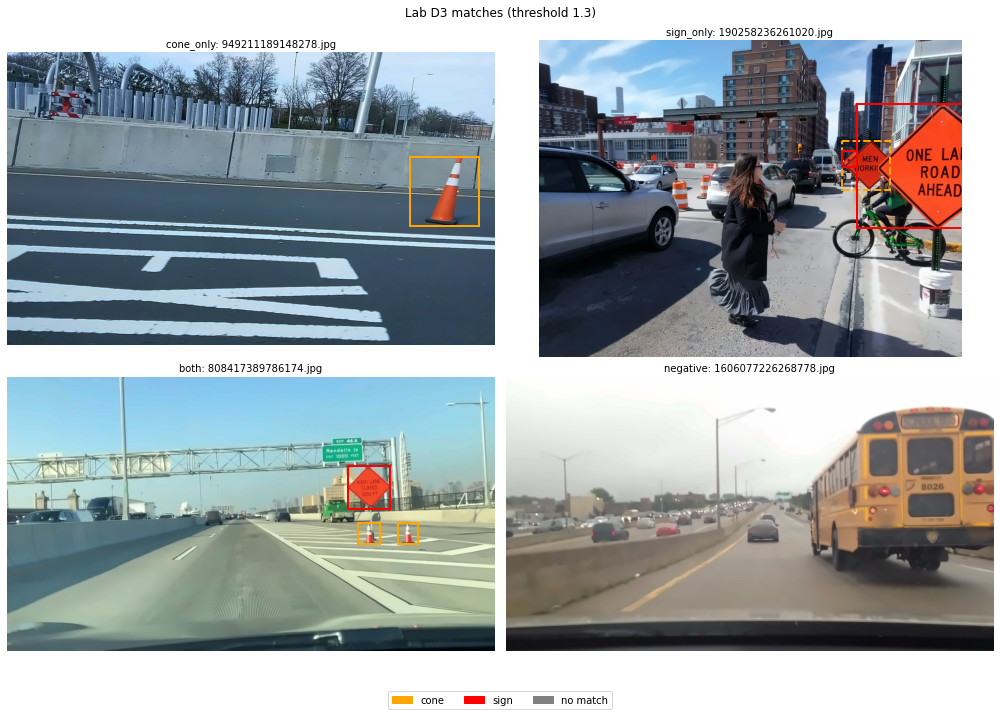

In [17]:
# Lab similarity matching with D3, same leave-one-image-out setup as the HSV version. Lab vectors have 40 bins,
# so they get their own threshold.
LAB_D3_THRESHOLD = 1.3  # placeholder: to be tuned with precision/recall

lab_matches = match_objects(lab_features, LAB_D3_THRESHOLD)
summarize_matches(lab_matches)
show_matches(LAB, lab_matches, f"Lab D3 matches (threshold {LAB_D3_THRESHOLD})")
